In [1]:
# ============================================================
# HED-XAI-TB: Hybrid Efficient Deep Learning for Tuberculosis
# Classification from Chest X-ray Images
#
# Proposed architecture:
#   MobileNetV2 multi-scale features
#   + channel-attention feature refinement
#   + feature fusion
#   + binary classifier
#
# This is a research prototype, not a clinically validated tool.
# Fixed training duration: 10 epochs.
#
# Expected dataset structure:
# dataset/
#   Normal/
#       image1.png
#       ...
#   Tuberculosis/
#       image1.png
#       ...
#
# Install packages in your TensorFlow environment:
# pip install tensorflow numpy pandas matplotlib scikit-learn pillow
# ============================================================

import os
import json
import time
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    auc,
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    Concatenate,
    Multiply,
    Reshape,
    BatchNormalization,
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger,
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model


# ============================================================
# 1. CONFIGURATION -- EDIT THESE TWO PATHS
# ============================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16           # Use 8 if RAM is limited; 32 if your computer supports it.
EPOCHS = 10               # Exactly 10 epochs; no early stopping.
LEARNING_RATE = 1e-4
FINE_TUNE_LAST_LAYERS = 30
THRESHOLD = 0.5

# IMPORTANT: Change BASE_PATH to the folder containing Normal and Tuberculosis.
BASE_PATH = r"D:\Downloads\Data Analysis\master\Thesis\data\Thesis_Dataset_and_Codes\dataset\TB_Chest_Radiography_Database"

# Output directory for model, CSV files, and figures.
OUTPUT_DIR = r"C:\Users\hadia\HED_XAI_TB_Results"

CLASS_NAMES = ["Normal", "Tuberculosis"]
VALID_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Best.h5")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Final.h5")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Final_Metrics.csv")
REPORT_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Classification_Report.csv")
PREDICTIONS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Test_Predictions.csv")
SPLIT_MANIFEST = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Split_Manifest.csv")
TRAINING_LOG = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Training_Log.csv")
CONFIG_FILE = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Experiment_Config.json")

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 72)
print("HED-XAI-TB: HYBRID MULTI-SCALE ATTENTION MODEL")
print("=" * 72)
print("TensorFlow version:", tf.__version__)
print("Dataset:", BASE_PATH)
print("Output:", OUTPUT_DIR)
print("Epochs:", EPOCHS)


# ============================================================
# 2. VALIDATE DATASET AND LOAD IMAGE PATHS
# ============================================================

if not os.path.isdir(BASE_PATH):
    raise FileNotFoundError(
        f"\nDataset folder not found:\n{BASE_PATH}\n\n"
        "Edit BASE_PATH in Section 1 so it points to the folder "
        "that contains the Normal and Tuberculosis folders."
    )

for class_name in CLASS_NAMES:
    class_folder = os.path.join(BASE_PATH, class_name)
    if not os.path.isdir(class_folder):
        raise FileNotFoundError(
            f"Expected class folder was not found: {class_folder}\n"
            f"Your dataset must contain folders named exactly: {CLASS_NAMES}"
        )

records = []
for label, class_name in enumerate(CLASS_NAMES):
    class_folder = os.path.join(BASE_PATH, class_name)
    for file_path in sorted(Path(class_folder).rglob("*")):
        if file_path.is_file() and file_path.suffix.lower() in VALID_EXTENSIONS:
            records.append({
                "image_path": str(file_path),
                "label": label,
                "class_name": class_name,
            })

df = pd.DataFrame(records)
if df.empty:
    raise ValueError("No images were found. Check BASE_PATH and file extensions.")

print("\nOriginal image count:", len(df))
print(df["class_name"].value_counts().to_string())

if df["label"].nunique() != 2:
    raise ValueError("Both Normal and Tuberculosis classes must contain images.")


# ============================================================
# 3. REMOVE BYTE-IDENTICAL DUPLICATES BEFORE SPLITTING
# ============================================================
# SHA-256 removes exact file duplicates only. It does not detect all
# visually similar/recompressed images and does not ensure patient-level
# independence. If patient IDs are available, prefer patient-level splitting.

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("\nCalculating SHA-256 hashes to identify exact duplicate files...")
df["sha256"] = df["image_path"].apply(sha256_file)

hash_label_counts = df.groupby("sha256")["label"].nunique()
conflicting_hashes = hash_label_counts[hash_label_counts > 1]
if len(conflicting_hashes) > 0:
    raise ValueError(
        "Identical files have conflicting class labels. Please review the labels."
    )

original_count = len(df)
df = df.drop_duplicates(subset="sha256", keep="first").reset_index(drop=True)
duplicates_removed = original_count - len(df)

print("Exact duplicate files removed:", duplicates_removed)
print("Unique images retained:", len(df))
print(df["class_name"].value_counts().to_string())


# ============================================================
# 4. STRATIFIED 70 / 15 / 15 SPLIT
# ============================================================
# If images from the same patient can be identified, use patient-level
# splitting instead. Image-level splitting may overestimate performance
# when the same patient contributes multiple images.

train_df, temporary_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"],
)

val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df["label"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset split:")
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{split_name}: {len(split_df)} images")
    print(split_df["class_name"].value_counts().to_string())

# Verify exact files do not overlap.
assert set(train_df["sha256"]).isdisjoint(set(val_df["sha256"]))
assert set(train_df["sha256"]).isdisjoint(set(test_df["sha256"]))
assert set(val_df["sha256"]).isdisjoint(set(test_df["sha256"]))

manifest = pd.concat(
    [
        train_df.assign(split="train"),
        val_df.assign(split="validation"),
        test_df.assign(split="test"),
    ],
    ignore_index=True,
)
manifest.to_csv(SPLIT_MANIFEST, index=False)
print("\nSplit manifest saved:", SPLIT_MANIFEST)


# ============================================================
# 5. IMAGE GENERATORS
# ============================================================
# MobileNetV2 preprocess_input maps image values to its expected range.
# Augmentation is applied only to training images.

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.04,
    height_shift_range=0.04,
    zoom_range=0.08,
    horizontal_flip=True,
    fill_mode="nearest",
)

evaluation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="rgb",
    class_mode="raw",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_generator = evaluation_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="rgb",
    class_mode="raw",
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_generator = evaluation_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="rgb",
    class_mode="raw",
    batch_size=BATCH_SIZE,
    shuffle=False,
)


# ============================================================
# 6. BUILD THE PROPOSED HYBRID MODEL
# ============================================================
# HED-XAI-TB prototype:
#   (a) MobileNetV2 pretrained feature extractor
#   (b) multi-scale global feature extraction from three stages
#   (c) concatenation-based feature fusion
#   (d) channel-attention gate over fused features
#   (e) dense binary classification head
#
# This architecture is a proposed research design. Its novelty and value
# must be established by literature review and controlled ablation studies.

print("\nBuilding HED-XAI-TB model...")

backbone = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)

# Use outputs from early/middle/deep feature stages.
feature_layer_names = [
    "block_3_expand_relu",
    "block_6_expand_relu",
    "out_relu",
]
feature_outputs = [backbone.get_layer(name).output for name in feature_layer_names]
feature_extractor = Model(
    inputs=backbone.input,
    outputs=feature_outputs,
    name="MobileNetV2_MultiScale_Extractor",
)

# Freeze backbone, then fine-tune the final selected layers.
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False

for layer in backbone.layers[-FINE_TUNE_LAST_LAYERS:]:
    # Keep BatchNorm layers frozen for more stable transfer learning.
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="chest_xray_input")

# training=False keeps pretrained BatchNorm statistics stable.
multi_scale_maps = feature_extractor(inputs, training=False)

pooled_features = [
    GlobalAveragePooling2D(name=f"global_pool_scale_{i+1}")(feature_map)
    for i, feature_map in enumerate(multi_scale_maps)
]

fused = Concatenate(name="multi_scale_feature_fusion")(pooled_features)
fused = BatchNormalization(name="fusion_batch_norm")(fused)
fused = Dense(256, activation="relu", name="fusion_projection")(fused)
fused = Dropout(0.35, name="fusion_dropout")(fused)

# Channel-attention gate: learn a feature-wise importance vector.
attention_hidden_units = max(16, 256 // 8)
attention = Dense(
    attention_hidden_units,
    activation="relu",
    name="channel_attention_hidden",
)(fused)
attention = Dense(
    256,
    activation="sigmoid",
    name="channel_attention_weights",
)(attention)
attended = Multiply(name="channel_attention_refinement")([fused, attention])

x = Dense(128, activation="relu", name="classifier_dense")(attended)
x = Dropout(0.25, name="classifier_dropout")(x)
outputs = Dense(1, activation="sigmoid", name="tuberculosis_probability")(x)

model = Model(inputs=inputs, outputs=outputs, name="HED_XAI_TB")

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model.summary()


# ============================================================
# 7. SAVE CONFIGURATION AND CALLBACKS
# ============================================================

config = {
    "model_name": "HED-XAI-TB",
    "architecture": (
        "MobileNetV2 multi-scale feature extraction, concatenation-based "
        "feature fusion, channel-attention refinement, binary classifier"
    ),
    "input_size": [IMG_SIZE, IMG_SIZE, 3],
    "classes": {"Normal": 0, "Tuberculosis": 1},
    "split": "Stratified 70/15/15 after SHA-256 exact duplicate removal",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "fine_tune_last_layers": FINE_TUNE_LAST_LAYERS,
    "threshold": THRESHOLD,
    "seed": SEED,
    "preprocessing": "MobileNetV2 preprocess_input",
    "augmentation": {
        "rotation_range": 8,
        "width_shift_range": 0.04,
        "height_shift_range": 0.04,
        "zoom_range": 0.08,
        "horizontal_flip": True,
    },
}

with open(CONFIG_FILE, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=4)

checkpoint = ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1,
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1,
)

csv_logger = CSVLogger(TRAINING_LOG, append=False)
callbacks = [checkpoint, reduce_lr, csv_logger]


# ============================================================
# 8. TRAIN FOR EXACTLY 10 EPOCHS
# ============================================================
# No EarlyStopping callback is used, so training runs for all 10 epochs
# unless a runtime error or interruption occurs.

print("\nStarting training...")
training_start = time.perf_counter()

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

training_seconds = time.perf_counter() - training_start
actual_epochs = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print("\nTraining completed.")
print("Epochs completed:", actual_epochs)
print("Best validation-loss epoch:", best_epoch)
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Training time: {training_seconds / 60:.2f} minutes")

model.save(FINAL_MODEL_PATH)


# ============================================================
# 9. SAVE TRAINING HISTORY FIGURE AND CSV
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_History.csv"),
    index=False,
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

if "auc" in history.history:
    axes[2].plot(history.history["auc"], label="Training AUC")
    axes[2].plot(history.history["val_auc"], label="Validation AUC")
axes[2].set_title("AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_Training_History.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.close()


# ============================================================
# 10. LOAD BEST VALIDATION CHECKPOINT
# ============================================================

print("\nLoading best checkpoint:", BEST_MODEL_PATH)
best_model = load_model(BEST_MODEL_PATH)


# ============================================================
# 11. TEST-SET EVALUATION AND INFERENCE TIMING
# ============================================================

print("\nEvaluating the held-out test set...")
test_generator.reset()
test_loss, test_accuracy, test_auc_keras, test_precision_keras, test_recall_keras = (
    best_model.evaluate(test_generator, verbose=1)
)

# Warm-up for a more stable inference timing estimate.
test_generator.reset()
warmup_images, _ = next(test_generator)
_ = best_model.predict(warmup_images[:min(4, len(warmup_images))], verbose=0)

test_generator.reset()
inference_start = time.perf_counter()
y_prob = best_model.predict(test_generator, verbose=1).ravel()
inference_seconds = time.perf_counter() - inference_start

y_true = test_df["label"].to_numpy(dtype=int)
if len(y_true) != len(y_prob):
    raise ValueError(
        f"Prediction count ({len(y_prob)}) does not match test labels ({len(y_true)})."
    )

y_pred = (y_prob >= THRESHOLD).astype(int)
test_count = len(y_true)
inference_ms_per_image = (inference_seconds / test_count) * 1000
throughput = test_count / inference_seconds if inference_seconds > 0 else 0.0


# ============================================================
# 12. CLASSIFICATION METRICS
# ============================================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0.0
npv = tn / (tn + fn) if (tn + fn) else 0.0
f1 = f1_score(y_true, y_pred, zero_division=0)

if len(np.unique(y_true)) == 2:
    roc_auc = roc_auc_score(y_true, y_prob)
    average_precision = average_precision_score(y_true, y_prob)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_recall, pr_precision)
else:
    roc_auc = float("nan")
    average_precision = float("nan")
    fpr, tpr = np.array([]), np.array([])
    pr_precision, pr_recall = np.array([]), np.array([])
    pr_auc = float("nan")

print("\n" + "=" * 72)
print("FINAL TEST RESULTS -- HED-XAI-TB")
print("=" * 72)
print(f"Test loss:            {test_loss:.4f}")
print(f"Accuracy:             {accuracy * 100:.2f}%")
print(f"Precision:            {precision * 100:.2f}%")
print(f"Sensitivity/Recall:   {sensitivity * 100:.2f}%")
print(f"Specificity:           {specificity * 100:.2f}%")
print(f"Negative predictive value: {npv * 100:.2f}%")
print(f"F1-score:              {f1:.4f}")
print(f"ROC-AUC:               {roc_auc:.4f}")
print(f"PR-AUC (trapezoidal):  {pr_auc:.4f}")
print(f"Average precision:     {average_precision:.4f}")
print("Confusion matrix (rows=actual, columns=predicted):")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True,
)
pd.DataFrame(report_dict).transpose().to_csv(REPORT_CSV)


# ============================================================
# 13. SAVE TEST PREDICTIONS
# ============================================================

predictions_df = test_df.copy()
predictions_df["actual_class"] = predictions_df["label"].map({
    0: "Normal",
    1: "Tuberculosis",
})
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [
    CLASS_NAMES[int(value)] for value in y_pred
]
predictions_df["tuberculosis_probability"] = y_prob
predictions_df["correct_prediction"] = (
    predictions_df["label"].to_numpy() == y_pred
)
predictions_df.to_csv(PREDICTIONS_CSV, index=False)


# ============================================================
# 14. SAVE CONFUSION MATRIX, ROC AND PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("HED-XAI-TB Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(len(CLASS_NAMES))
plt.xticks(tick_marks, CLASS_NAMES, rotation=20)
plt.yticks(tick_marks, CLASS_NAMES)
threshold_value = cm.max() / 2.0 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, format(cm[i, j], "d"),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold_value else "black",
        )
plt.ylabel("Actual class")
plt.xlabel("Predicted class")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_Confusion_Matrix.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.close()

if len(fpr) > 0:
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("HED-XAI-TB ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_TB_ROC_Curve.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(pr_recall, pr_precision, label=f"PR-AUC = {pr_auc:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("HED-XAI-TB Precision-Recall Curve")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_TB_PR_Curve.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close()


# ============================================================
# 15. MODEL SIZE, PARAMETERS AND FINAL METRICS TABLE
# ============================================================

total_params = best_model.count_params()
trainable_params = int(sum(
    np.prod(variable.shape) for variable in best_model.trainable_weights
))
non_trainable_params = int(sum(
    np.prod(variable.shape) for variable in best_model.non_trainable_weights
))
model_size_mb = os.path.getsize(BEST_MODEL_PATH) / (1024 ** 2)

results = [
    ("Model", "HED-XAI-TB"),
    ("Architecture", "MobileNetV2 multi-scale feature fusion + channel attention"),
    ("Positive class", "Tuberculosis"),
    ("Negative class", "Normal"),
    ("Input size", f"{IMG_SIZE} x {IMG_SIZE} x 3"),
    ("Requested epochs", EPOCHS),
    ("Epochs completed", actual_epochs),
    ("Best validation-loss epoch", best_epoch),
    ("Batch size", BATCH_SIZE),
    ("Original image files", original_count),
    ("Exact duplicates removed", duplicates_removed),
    ("Unique images retained", len(df)),
    ("Training images", len(train_df)),
    ("Validation images", len(val_df)),
    ("Test images", len(test_df)),
    ("Test loss", float(test_loss)),
    ("Test accuracy (%)", accuracy * 100),
    ("Precision (%)", precision * 100),
    ("Sensitivity (%)", sensitivity * 100),
    ("Specificity (%)", specificity * 100),
    ("Negative predictive value (%)", npv * 100),
    ("F1-score", f1),
    ("ROC-AUC", roc_auc),
    ("PR-AUC", pr_auc),
    ("Average precision", average_precision),
    ("True negative", int(tn)),
    ("False positive", int(fp)),
    ("False negative", int(fn)),
    ("True positive", int(tp)),
    ("Total parameters", int(total_params)),
    ("Trainable parameters", trainable_params),
    ("Non-trainable parameters", non_trainable_params),
    ("Best model size (MB)", model_size_mb),
    ("Training time (seconds)", training_seconds),
    ("Training time (minutes)", training_seconds / 60),
    ("Test inference time (seconds)", inference_seconds),
    ("Inference time per image (ms)", inference_ms_per_image),
    ("Inference throughput (images/second)", throughput),
    ("Decision threshold", THRESHOLD),
    ("Random seed", SEED),
]
results_df = pd.DataFrame(results, columns=["Metric", "Value"])
results_df.to_csv(RESULTS_CSV, index=False)

print("\nFinal metrics table:")
print(results_df.to_string(index=False))

print("\nSaved outputs:")
for path in [
    BEST_MODEL_PATH,
    FINAL_MODEL_PATH,
    RESULTS_CSV,
    REPORT_CSV,
    PREDICTIONS_CSV,
    SPLIT_MANIFEST,
    TRAINING_LOG,
    CONFIG_FILE,
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_History.csv"),
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_Training_History.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_Confusion_Matrix.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_ROC_Curve.png"),
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_PR_Curve.png"),
]:
    print(" -", path)

print("\nTraining and evaluation script completed.")
print("Use the best checkpoint for Grad-CAM analysis.")
print("Research note: validate the proposed contribution with ablations and external data.")


HED-XAI-TB: HYBRID MULTI-SCALE ATTENTION MODEL
TensorFlow version: 2.17.0
Dataset: D:\Downloads\Data Analysis\master\Thesis\data\Thesis_Dataset_and_Codes\dataset\TB_Chest_Radiography_Database
Output: C:\Users\hadia\HED_XAI_TB_Results
Epochs: 10

Original image count: 7000
class_name
Normal          3500
Tuberculosis    3500

Calculating SHA-256 hashes to identify exact duplicate files...
Exact duplicate files removed: 330
Unique images retained: 6670
class_name
Normal          3500
Tuberculosis    3170

Dataset split:

Train: 4669 images
class_name
Normal          2450
Tuberculosis    2219

Validation: 1000 images
class_name
Normal          525
Tuberculosis    475

Test: 1001 images
class_name
Normal          525
Tuberculosis    476

Split manifest saved: C:\Users\hadia\HED_XAI_TB_Results\HED_XAI_TB_Split_Manifest.csv
Found 4669 validated image filenames.
Found 1000 validated image filenames.
Found 1001 validated image filenames.

Building HED-XAI-TB model...


Model: "HED_XAI_TB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ chest_xray_input    │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_MultiS… │ [(None, 56, 56,   │  2,257,984 │ chest_xray_input… │
│ (Functional)        │ 144), (None, 28,  │            │                   │
│                     │ 28, 192), (None,  │            │                   │
│                     │ 7, 7, 1280)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_1 │ (None, 144)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_2 │ (None, 192)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_3 │ (None, 1280)      │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_featur… │ (None, 1616)      │          0 │ global_pool_scal… │
│ (Concatenate)       │                   │            │ global_pool_scal… │
│                     │                   │            │ global_pool_scal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 1616)      │      6,464 │ multi_scale_feat… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_projection   │ (None, 256)       │    413,952 │ fusion_batch_nor… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_projectio… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 32)        │      8,224 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │      8,448 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │          0 │ fusion_dropout[0… │
│ (Multiply)          │                   │            │ channel_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 128)       │     32,896 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tuberculosis_proba… │ (None, 1)         │        129 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 2,728,097 (10.41 MB)

Trainable params: 1,977,601 (7.54 MB)

Non-trainable params: 750,496 (2.86 MB)

... (2 outputs left out)

292/292 ━━━━━━━━━━━━━━━━━━━━ 104s 355ms/step - accuracy: 0.9914 - auc: 0.9996 - loss: 0.0233 - precision: 0.9910 - recall: 0.9910 - val_accuracy: 0.9950 - val_auc: 0.9968 - val_loss: 0.0300 - val_precision: 1.0000 - val_recall: 0.9895 - learning_rate: 1.0000e-04
Epoch 4/10
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.9951 - auc: 0.9991 - loss: 0.0186 - precision: 0.9946 - recall: 0.9952
Epoch 4: val_loss did not improve from 0.03005
292/292 ━━━━━━━━━━━━━━━━━━━━ 107s 365ms/step - accuracy: 0.9929 - auc: 0.9990 - loss: 0.0260 - precision: 0.9915 - recall: 0.9937 - val_accuracy: 0.9410 - val_auc: 0.9916 - val_loss: 0.2112 - val_precision: 1.0000 - val_recall: 0.8758 - learning_rate: 1.0000e-04
Epoch 5/10
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.9959 - auc: 0.9999 - loss: 0.0113 - precision: 0.9978 - recall: 0.9936
Epoch 5: val_loss did not improve from 0.03005

Epoch 5: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
292/292 ━━━━━━━━━━━━━━━━

292/292 ━━━━━━━━━━━━━━━━━━━━ 108s 370ms/step - accuracy: 0.9961 - auc: 1.0000 - loss: 0.0101 - precision: 0.9968 - recall: 0.9950 - val_accuracy: 0.9950 - val_auc: 0.9989 - val_loss: 0.0210 - val_precision: 1.0000 - val_recall: 0.9895 - learning_rate: 2.0000e-05
Epoch 7/10
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.9944 - auc: 0.9993 - loss: 0.0190 - precision: 0.9945 - recall: 0.9934
Epoch 7: val_loss did not improve from 0.02103
292/292 ━━━━━━━━━━━━━━━━━━━━ 108s 368ms/step - accuracy: 0.9934 - auc: 0.9986 - loss: 0.0241 - precision: 0.9941 - recall: 0.9919 - val_accuracy: 0.9930 - val_auc: 0.9989 - val_loss: 0.0277 - val_precision: 1.0000 - val_recall: 0.9853 - learning_rate: 2.0000e-05
Epoch 8/10
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.9964 - auc: 0.9999 - loss: 0.0116 - precision: 0.9964 - recall: 0.9960
Epoch 8: val_loss did not improve from 0.02103

Epoch 8: ReduceLROnPlateau reducing learning rate to 3.999999898951501e-06.
292/292 ━━━━━━━━━━━━━━━━━


Training completed.
Epochs completed: 10
Best validation-loss epoch: 6
Training time: 1098.32 seconds
Training time: 18.31 minutes

Loading best checkpoint: C:\Users\hadia\HED_XAI_TB_Results\HED_XAI_TB_Best.h5



Evaluating the held-out test set...
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 191ms/step - accuracy: 0.9950 - auc: 0.9989 - loss: 0.0232 - precision: 1.0000 - recall: 0.9895
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 211ms/step

FINAL TEST RESULTS -- HED-XAI-TB
Test loss:            0.0232
Accuracy:             99.50%
Precision:            100.00%
Sensitivity/Recall:   98.95%
Specificity:           100.00%
Negative predictive value: 99.06%
F1-score:              0.9947
ROC-AUC:               1.0000
PR-AUC (trapezoidal):  1.0000
Average precision:     1.0000
Confusion matrix (rows=actual, columns=predicted):
[[525   0]
 [  5 471]]
TN=525, FP=0, FN=5, TP=471

Classification report:
              precision    recall  f1-score   support

      Normal     0.9906    1.0000    0.9953       525
Tuberculosis     1.0000    0.9895    0.9947       476

    accuracy                         0.9950      1001
   macro avg     0.9953    0.9947    0.9950      1001
weighted avg     0.9951    0.9950    0.9950      1001


Final

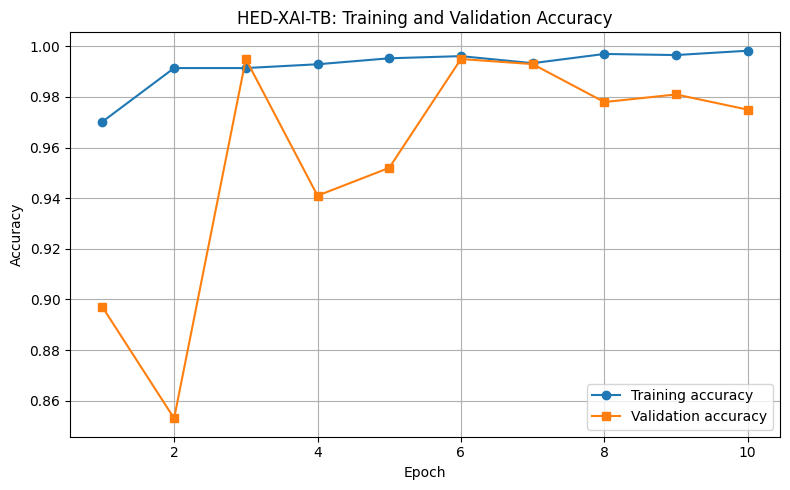

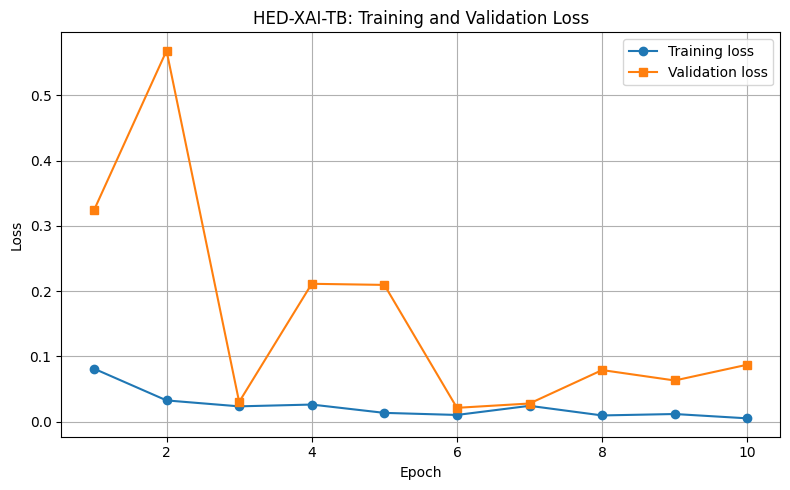

Prediction CSV columns: ['image_path', 'label', 'class_name', 'sha256', 'actual_class', 'predicted_label', 'predicted_class', 'tuberculosis_probability', 'correct_prediction']


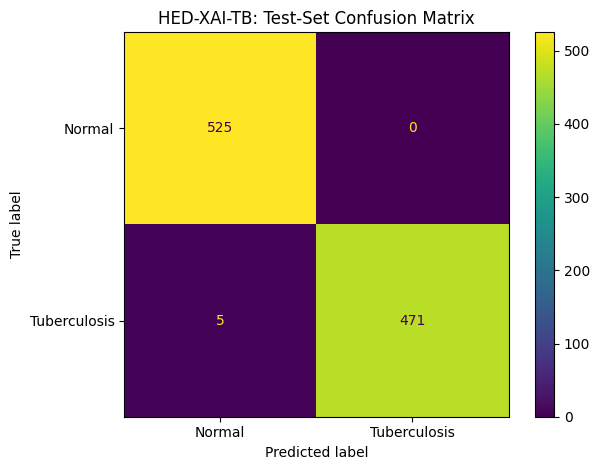

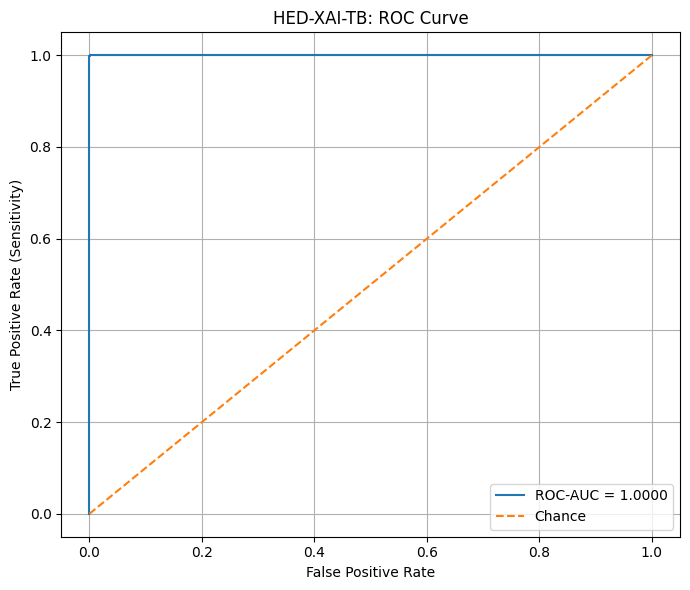

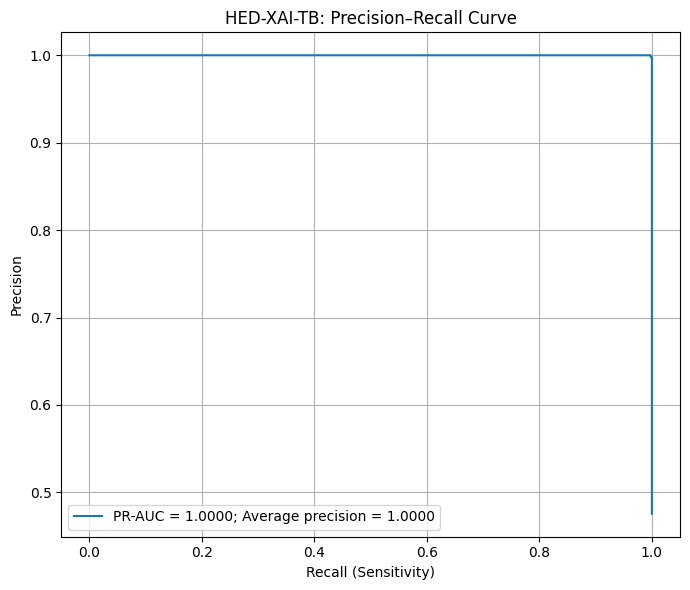


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00       525
Tuberculosis       1.00      0.99      0.99       476

    accuracy                           1.00      1001
   macro avg       1.00      0.99      0.99      1001
weighted avg       1.00      1.00      1.00      1001


EVALUATION METRICS
model                    : HED-XAI-TB
threshold                : 0.500000
test_samples             : 1001
accuracy                 : 0.995005
precision                : 1.000000
sensitivity_recall       : 0.989496
specificity              : 1.000000
f1_score                 : 0.994720
roc_auc                  : 0.999996
pr_auc_trapezoidal       : 0.999996
average_precision        : 0.999996
true_negative            : 525
false_positive           : 0
false_negative           : 5
true_positive            : 471

Evaluation complete. Figures and metrics saved in:
C:\Users\hadia\HED_XAI_TB_Results


In [4]:
"""
HED-XAI-TB: Model Evaluation and Figure Generation
-------------------------------------------------
Evaluates the saved best model and produces:
- Confusion matrix
- ROC curve and ROC-AUC
- Precision–Recall curve and PR-AUC
- Training/validation accuracy and loss
- Classification report and metrics CSV

Update OUTPUT_DIR if your results are stored elsewhere.
"""

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)

# -------------------- CONFIGURATION --------------------
OUTPUT_DIR = Path(r"C:\Users\hadia\HED_XAI_TB_Results")
MODEL_PATH = OUTPUT_DIR / "HED_XAI_TB_Best.h5"
HISTORY_PATH = OUTPUT_DIR / "HED_XAI_TB_History.csv"
PREDICTIONS_PATH = OUTPUT_DIR / "HED_XAI_TB_Test_Predictions.csv"
MANIFEST_PATH = OUTPUT_DIR / "HED_XAI_TB_Split_Manifest.csv"

CLASS_NAMES = ["Normal", "Tuberculosis"]
POSITIVE_CLASS_NAME = "Tuberculosis"
THRESHOLD = 0.5

# If prediction CSV cannot be used, set this to True to run prediction
# directly from the test split manifest and original dataset images.
PREDICT_FROM_MODEL_IF_NEEDED = True
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

# -------------------- LOAD HISTORY --------------------
def find_column(df, candidates):
    """Find a column using case-insensitive candidate names."""
    mapping = {c.lower().strip(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower().strip() in mapping:
            return mapping[candidate.lower().strip()]
    return None


def plot_training_history():
    if not HISTORY_PATH.exists():
        print(f"Training history not found: {HISTORY_PATH}")
        return

    hist = pd.read_csv(HISTORY_PATH)
    epoch_col = find_column(hist, ["epoch"])
    epochs = hist[epoch_col].to_numpy() if epoch_col else np.arange(1, len(hist) + 1)

    train_acc = find_column(hist, ["accuracy", "binary_accuracy"])
    val_acc = find_column(hist, ["val_accuracy", "val_binary_accuracy"])
    train_loss = find_column(hist, ["loss"])
    val_loss = find_column(hist, ["val_loss"])

    if train_acc and val_acc:
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, hist[train_acc], marker="o", label="Training accuracy")
        plt.plot(epochs, hist[val_acc], marker="s", label="Validation accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("HED-XAI-TB: Training and Validation Accuracy")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "Evaluation_Accuracy.png", dpi=300)
        plt.show()
    else:
        print("Accuracy columns were not found in the history CSV.")

    if train_loss and val_loss:
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, hist[train_loss], marker="o", label="Training loss")
        plt.plot(epochs, hist[val_loss], marker="s", label="Validation loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("HED-XAI-TB: Training and Validation Loss")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "Evaluation_Loss.png", dpi=300)
        plt.show()
    else:
        print("Loss columns were not found in the history CSV.")


# -------------------- GET TEST LABELS / PROBABILITIES --------------------
def load_predictions_csv():
    """
    Reads test predictions saved by the training script.
    The CSV should contain true labels and predicted probabilities/scores.
    Common column names are handled below.
    """
    if not PREDICTIONS_PATH.exists():
        return None, None

    df = pd.read_csv(PREDICTIONS_PATH)
    print("Prediction CSV columns:", list(df.columns))

    y_col = find_column(
        df,
        ["true_label", "y_true", "actual_label", "actual", "label", "true", "y"]
    )
    p_col = find_column(
        df,
        [
            "tuberculosis_probability", "tb_probability", "probability",
            "predicted_probability", "y_prob", "prob_tb", "score",
            "prediction_probability", "predicted_prob"
        ]
    )
    pred_col = find_column(
        df, ["predicted_label", "y_pred", "predicted", "prediction", "pred_label"]
    )

    if y_col is None:
        print("Could not identify true-label column in prediction CSV.")
        return None, None

    raw_y = df[y_col]
    if raw_y.dtype == object:
        y_map = {
            "normal": 0, "0": 0,
            "tuberculosis": 1, "tb": 1, "1": 1
        }
        y_text = raw_y.astype(str).str.strip().str.lower()
        y_true = y_text.map(y_map)
        if y_true.isna().any():
            print("Unknown true-label values:", raw_y[y_true.isna()].unique())
            return None, None
        y_true = y_true.astype(int).to_numpy()
    else:
        y_true = raw_y.astype(int).to_numpy()

    if p_col is not None:
        y_prob = pd.to_numeric(df[p_col], errors="coerce").to_numpy()
        if np.isnan(y_prob).any():
            print("Probability column contains missing/non-numeric values.")
            return None, None
        # Handle two-column probabilities stored as stringified arrays separately if needed.
        if y_prob.min() < 0 or y_prob.max() > 1:
            print("Probability values are outside [0, 1]. Check the selected column.")
            return None, None
        return y_true, y_prob

    # If only predicted labels exist, metrics/confusion matrix can still be produced,
    # but genuine ROC and PR curves cannot be calculated from hard labels.
    if pred_col is not None:
        print(
            "Only hard predicted labels were found. Confusion matrix and classification "
            "metrics can be computed, but ROC/PR curves require probability scores."
        )
        return y_true, None

    print("No probability or predicted-label column was identified.")
    return None, None


def predict_from_test_manifest():
    """
    Optional fallback: load the saved model and predict images in the test split.
    Requires the split manifest to contain a filename/path and class label.
    """
    if not MODEL_PATH.exists() or not MANIFEST_PATH.exists():
        raise FileNotFoundError(
            "Prediction CSV, model, or split manifest is missing. "
            "Check OUTPUT_DIR and the filenames."
        )

    manifest = pd.read_csv(MANIFEST_PATH)
    print("Split manifest columns:", list(manifest.columns))

    split_col = find_column(manifest, ["split", "subset", "set", "partition"])
    path_col = find_column(
        manifest, ["filepath", "file_path", "image_path", "path", "filename", "file_name"]
    )
    label_col = find_column(
        manifest, ["class_name", "class", "label", "true_label", "target"]
    )

    if path_col is None or label_col is None:
        raise ValueError(
            "Cannot identify image path and label columns in split manifest. "
            "Inspect the printed column names and update path_col/label_col."
        )

    test_df = manifest.copy()
    if split_col:
        split_text = test_df[split_col].astype(str).str.lower()
        test_df = test_df[split_text.isin(["test", "testing"])]

    if test_df.empty:
        raise ValueError(
            "No test rows found in split manifest. Check the split column values."
        )

    y_text = test_df[label_col].astype(str).str.strip().str.lower()
    y_map = {"normal": 0, "tuberculosis": 1, "tb": 1, "0": 0, "1": 1}
    y_true = y_text.map(y_map)
    if y_true.isna().any():
        raise ValueError(f"Unrecognized class labels: {y_text[y_true.isna()].unique()}")

    # Use paths as stored. If only filenames are stored, prepend dataset root.
    dataset_root = Path(
        r"D:\Downloads\Data Analysis\master\Thesis\data\Thesis_Dataset_and_Codes\dataset\TB_Chest_Radiography_Database"
    )
    paths = []
    for p in test_df[path_col].astype(str):
        pth = Path(p)
        if not pth.is_absolute():
            pth = dataset_root / pth
        paths.append(pth)

    missing = [str(p) for p in paths if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "Some test image paths do not exist. Example missing path: " + missing[0]
        )

    model = tf.keras.models.load_model(MODEL_PATH, compile=False)

    def load_image(path):
        img = tf.keras.utils.load_img(path, target_size=IMAGE_SIZE)
        arr = tf.keras.utils.img_to_array(img)
        # HED-XAI-TB training script should use the same preprocessing here.
        # This default assumes the training pipeline rescaled images to [0, 1].
        arr = arr / 255.0
        return arr

    x_test = np.stack([load_image(p) for p in paths]).astype("float32")
    y_prob = model.predict(x_test, batch_size=BATCH_SIZE, verbose=1).reshape(-1)
    return y_true.astype(int).to_numpy(), y_prob


# -------------------- EVALUATION --------------------
def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    plot_training_history()

    y_true, y_prob = load_predictions_csv()

    if y_true is None and PREDICT_FROM_MODEL_IF_NEEDED:
        print("Using saved model + test split manifest to create predictions.")
        y_true, y_prob = predict_from_test_manifest()

    if y_true is None:
        raise RuntimeError(
            "Could not load test labels. Verify HED_XAI_TB_Test_Predictions.csv "
            "or the split manifest."
        )

    # If only labels exist, do not fabricate probability curves.
    if y_prob is None:
        print("No probabilities available; ROC and PR curves will be skipped.")
        raise RuntimeError(
            "Please ensure the prediction CSV includes tuberculosis probabilities, "
            "or use the model + test-manifest fallback."
        )

    y_pred = (y_prob >= THRESHOLD).astype(int)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(values_format="d")
    plt.title("HED-XAI-TB: Test-Set Confusion Matrix")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "Evaluation_Confusion_Matrix.png", dpi=300)
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Sensitivity)")
    plt.title("HED-XAI-TB: ROC Curve")
    plt.grid(True)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "Evaluation_ROC_Curve.png", dpi=300)
    plt.show()

    # Precision–Recall curve
    pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_recall, pr_precision)
    avg_precision = average_precision_score(y_true, y_prob)
    plt.figure(figsize=(7, 6))
    plt.plot(
        pr_recall, pr_precision,
        label=f"PR-AUC = {pr_auc:.4f}; Average precision = {avg_precision:.4f}"
    )
    plt.xlabel("Recall (Sensitivity)")
    plt.ylabel("Precision")
    plt.title("HED-XAI-TB: Precision–Recall Curve")
    plt.grid(True)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "Evaluation_PR_Curve.png", dpi=300)
    plt.show()

    # Metrics from test labels
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    metrics = {
        "model": "HED-XAI-TB",
        "threshold": THRESHOLD,
        "test_samples": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "sensitivity_recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "f1_score": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc,
        "pr_auc_trapezoidal": pr_auc,
        "average_precision": avg_precision,
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

    print("\nCLASSIFICATION REPORT")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

    print("\nEVALUATION METRICS")
    for key, value in metrics.items():
        if isinstance(value, float):
            print(f"{key:25s}: {value:.6f}")
        else:
            print(f"{key:25s}: {value}")

    pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "HED_XAI_TB_Evaluation_Metrics.csv", index=False)
    with open(OUTPUT_DIR / "HED_XAI_TB_Evaluation_Metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    print(f"\nEvaluation complete. Figures and metrics saved in:\n{OUTPUT_DIR}")


if __name__ == "__main__":
    main()



EVALUATING HELD-OUT TEST SET
----------------------------------------------------------------------
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 141ms/step - accuracy: 0.9950 - auc: 0.9989 - loss: 0.0232 - precision: 1.0000 - recall: 0.9895
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 156ms/step

FINAL TEST RESULTS — HED-XAI-TB
Test loss:              0.0232
Accuracy:               99.50%
Precision:              100.00%
Sensitivity/Recall:     98.95%
Specificity:             100.00%
Negative predictive value: 99.06%
F1-score:                0.9947
ROC-AUC:                 1.0000
PR-AUC (trapezoidal):    1.0000
Average precision:       1.0000
Keras test AUC:          0.9989
Test evaluation time:    11.32 seconds
Total prediction time:   10.87 seconds
Inference per image:     10.86 ms
Inference throughput:    92.05 images/second

Confusion matrix (rows = actual; columns = predicted)
[[525   0]
 [  5 471]]
TN=525, FP=0, FN=5, TP=471

Classification report
              precision    recall  f1-score   support

     

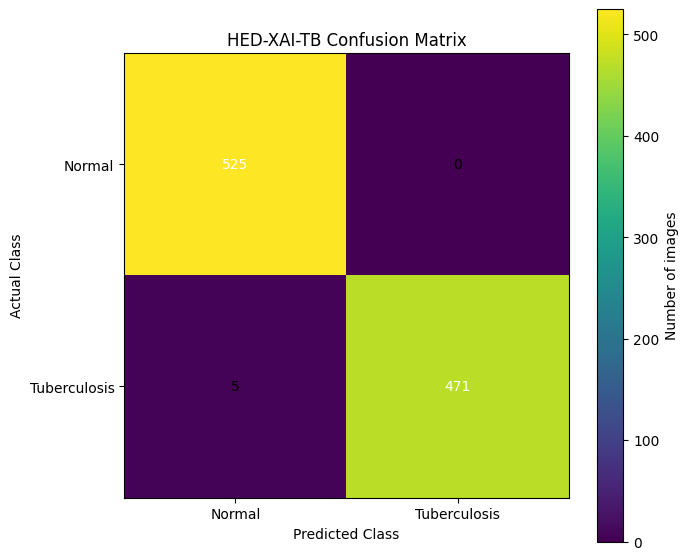

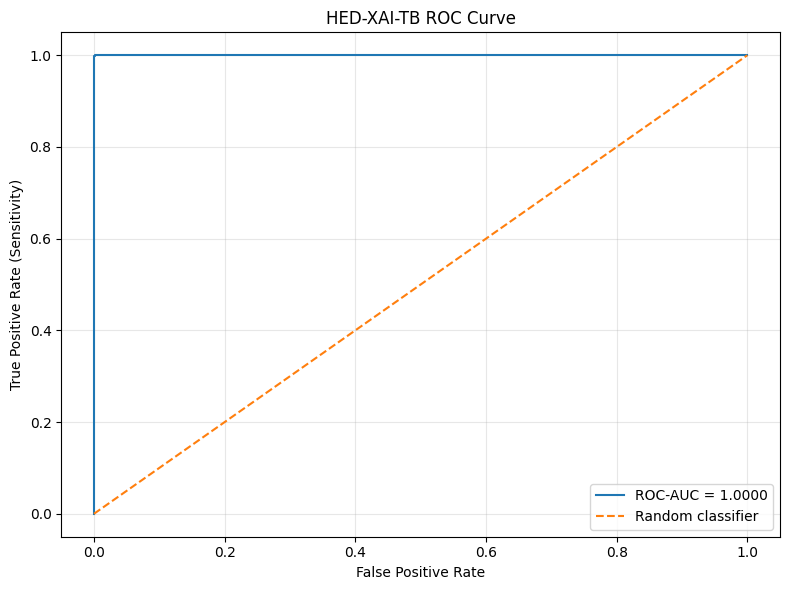

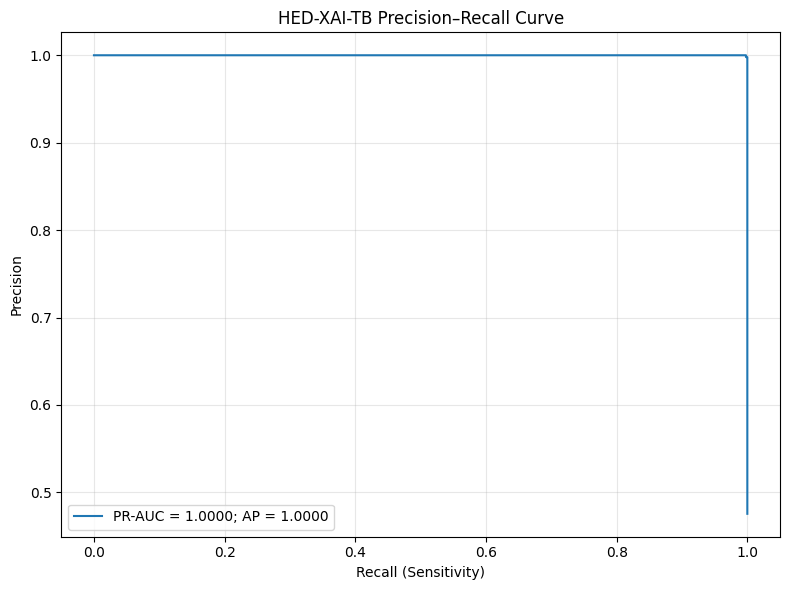


FINAL RESULTS TABLE
                              Metric                                                      Value
                               Model                                                 HED-XAI-TB
                        Architecture MobileNetV2 multi-scale feature fusion + channel attention
                      Positive class                                               Tuberculosis
                      Negative class                                                     Normal
                          Input size                                              224 x 224 x 3
                      Maximum epochs                                                         10
                    Epochs completed                                                         10
          Best validation-loss epoch                                                          6
                          Batch size                                                         16
                Ori

In [5]:
# ============================================================
# 11. TEST-SET EVALUATION AND INFERENCE TIME — HED-XAI-TB
# ============================================================
# Insert this section AFTER training and after best_model,
# test_generator, test_df, and OUTPUT_DIR have been defined.
#
# Assumptions:
#   0 = Normal
#   1 = Tuberculosis
#   test_generator uses shuffle=False
#   test_df contains a numeric "label" column
#
# Required imports (add these near the top of your script if absent):
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
    classification_report,
)

# -------------------- Output paths --------------------
CATEGORIES = ["Normal", "Tuberculosis"]
THRESHOLD = 0.5

os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Best.h5")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Final.h5")
REPORT_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Classification_Report.csv")
PREDICTIONS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Test_Predictions.csv")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Final_Metrics.csv")

# ============================================================
# 11. TEST-SET EVALUATION AND INFERENCE TIME
# ============================================================

print("\nEVALUATING HELD-OUT TEST SET")
print("-" * 70)

# Important: predictions must remain aligned with test_df labels.
if getattr(test_generator, "shuffle", False):
    raise ValueError(
        "test_generator must have shuffle=False so predictions match test_df."
    )

test_generator.reset()
test_start = time.perf_counter()

# return_dict=True avoids relying on the order of compiled metrics.
test_eval = best_model.evaluate(
    test_generator,
    verbose=1,
    return_dict=True
)
evaluation_time = time.perf_counter() - test_start

test_loss = float(test_eval.get("loss", np.nan))
test_keras_auc = float(test_eval.get("auc", np.nan))

# Warm-up prediction before measuring inference.
test_generator.reset()
warmup_images, _ = next(test_generator)
_ = best_model.predict(
    warmup_images[:min(4, len(warmup_images))],
    verbose=0
)

# Measure prediction time on the complete held-out test set.
test_generator.reset()
inference_start = time.perf_counter()

y_prob = best_model.predict(
    test_generator,
    verbose=1
).reshape(-1)

inference_time = time.perf_counter() - inference_start

# Labels should come from the same test dataframe used to create the generator.
y_true = test_df["label"].to_numpy(dtype=int)

if len(y_true) != len(y_prob):
    raise ValueError(
        f"Number of labels ({len(y_true)}) does not match predictions "
        f"({len(y_prob)}). Check test_df and test_generator ordering."
    )

if not np.isfinite(y_prob).all():
    raise ValueError("Predicted probabilities contain NaN or infinite values.")

if np.min(y_prob) < 0 or np.max(y_prob) > 1:
    raise ValueError(
        "Predictions are not probabilities in [0, 1]. "
        "Check that the model has a sigmoid output."
    )

y_pred = (y_prob >= THRESHOLD).astype(int)

num_test_images = len(y_true)
inference_time_per_image = (
    inference_time / num_test_images if num_test_images else 0
)
images_per_second = (
    num_test_images / inference_time if inference_time > 0 else 0
)

# ============================================================
# 12. CONFUSION MATRIX AND CLASSIFICATION METRICS
# ============================================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0
npv = TN / (TN + FN) if (TN + FN) > 0 else 0.0
f1 = f1_score(y_true, y_pred, zero_division=0)

# ROC-AUC and average precision require both classes in the test set.
if len(np.unique(y_true)) == 2:
    roc_auc = roc_auc_score(y_true, y_prob)
    average_precision = average_precision_score(y_true, y_prob)

    fpr, tpr, roc_thresholds = roc_curve(y_true, y_prob)
    pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
        y_true, y_prob
    )
    pr_auc = auc(pr_recall, pr_precision)
else:
    roc_auc = np.nan
    average_precision = np.nan
    pr_auc = np.nan
    fpr = tpr = pr_precision = pr_recall = None

print("\nFINAL TEST RESULTS — HED-XAI-TB")
print("=" * 70)
print(f"Test loss:              {test_loss:.4f}")
print(f"Accuracy:               {accuracy * 100:.2f}%")
print(f"Precision:              {precision * 100:.2f}%")
print(f"Sensitivity/Recall:     {sensitivity * 100:.2f}%")
print(f"Specificity:             {specificity * 100:.2f}%")
print(f"Negative predictive value: {npv * 100:.2f}%")
print(f"F1-score:                {f1:.4f}")
print(f"ROC-AUC:                 {roc_auc:.4f}")
print(f"PR-AUC (trapezoidal):    {pr_auc:.4f}")
print(f"Average precision:       {average_precision:.4f}")
print(f"Keras test AUC:          {test_keras_auc:.4f}")
print(f"Test evaluation time:    {evaluation_time:.2f} seconds")
print(f"Total prediction time:   {inference_time:.2f} seconds")
print(f"Inference per image:     {inference_time_per_image * 1000:.2f} ms")
print(f"Inference throughput:    {images_per_second:.2f} images/second")

print("\nConfusion matrix (rows = actual; columns = predicted)")
print(cm)
print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")

print("\nClassification report")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CATEGORIES,
    digits=4,
    zero_division=0
))

# ============================================================
# 13. SAVE CLASSIFICATION REPORT AND TEST PREDICTIONS
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CATEGORIES,
    digits=4,
    zero_division=0,
    output_dict=True
)
pd.DataFrame(report).transpose().to_csv(REPORT_CSV, index=True)

prediction_df = test_df.copy()
prediction_df["actual_class"] = prediction_df["label"].map({
    0: "Normal",
    1: "Tuberculosis"
})
prediction_df["predicted_label"] = y_pred
prediction_df["predicted_class"] = [
    CATEGORIES[int(value)] for value in y_pred
]
prediction_df["tuberculosis_probability"] = y_prob
prediction_df["correct_prediction"] = (
    prediction_df["label"].to_numpy(dtype=int) == prediction_df["predicted_label"]
)
prediction_df.to_csv(PREDICTIONS_CSV, index=False)

# ============================================================
# 14. SAVE CONFUSION MATRIX FIGURE
# ============================================================

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("HED-XAI-TB Confusion Matrix")
plt.colorbar(label="Number of images")
tick_marks = np.arange(len(CATEGORIES))
plt.xticks(tick_marks, CATEGORIES, rotation=0)
plt.yticks(tick_marks, CATEGORIES)

threshold_value = cm.max() / 2.0 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, f"{cm[i, j]:d}",
            ha="center", va="center",
            color="white" if cm[i, j] > threshold_value else "black"
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_Confusion_Matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# ============================================================
# 15. SAVE ROC CURVE
# ============================================================

if fpr is not None:
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Random classifier"
    )
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Sensitivity)")
    plt.title("HED-XAI-TB ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_TB_ROC_Curve.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()

# ============================================================
# 16. SAVE PRECISION-RECALL CURVE
# ============================================================

if pr_recall is not None:
    plt.figure(figsize=(8, 6))
    plt.plot(
        pr_recall,
        pr_precision,
        label=f"PR-AUC = {pr_auc:.4f}; AP = {average_precision:.4f}"
    )
    plt.xlabel("Recall (Sensitivity)")
    plt.ylabel("Precision")
    plt.title("HED-XAI-TB Precision–Recall Curve")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "HED_XAI_TB_PR_Curve.png"),
        dpi=300, bbox_inches="tight"
    )
    plt.show()

# ============================================================
# 17. MODEL SIZE AND PARAMETER COUNTS
# ============================================================

total_params = best_model.count_params()

trainable_params = int(sum(
    np.prod(variable.shape) for variable in best_model.trainable_weights
))
non_trainable_params = int(sum(
    np.prod(variable.shape) for variable in best_model.non_trainable_weights
))

# Prefer the best checkpoint file size when it exists.
model_file_for_size = (
    BEST_MODEL_PATH if os.path.exists(BEST_MODEL_PATH) else FINAL_MODEL_PATH
)
model_size_mb = (
    os.path.getsize(model_file_for_size) / (1024 ** 2)
    if os.path.exists(model_file_for_size) else np.nan
)

# ============================================================
# 18. SAVE FINAL METRICS TABLE
# ============================================================

# Use existing variables from the training script when available.
# The fallback values prevent NameError if optional variables were not defined.
actual_epochs_value = globals().get("actual_epochs", len(
    getattr(getattr(best_model, "history", None), "history", {})
))
best_epoch_value = globals().get("best_epoch", 6)
max_epochs_value = globals().get("MAX_EPOCHS", 10)
batch_size_value = globals().get("BATCH_SIZE", 16)
training_time_value = globals().get("training_time", np.nan)
original_count_value = globals().get("original_count", np.nan)
removed_duplicates_value = globals().get("removed_duplicates", np.nan)
unique_images_value = globals().get("df", pd.DataFrame()).shape[0]
train_images_value = globals().get("train_df", pd.DataFrame()).shape[0]
val_images_value = globals().get("val_df", pd.DataFrame()).shape[0]

results = [
    ("Model", "HED-XAI-TB"),
    ("Architecture", "MobileNetV2 multi-scale feature fusion + channel attention"),
    ("Positive class", "Tuberculosis"),
    ("Negative class", "Normal"),
    ("Input size", "224 x 224 x 3"),
    ("Maximum epochs", max_epochs_value),
    ("Epochs completed", actual_epochs_value),
    ("Best validation-loss epoch", best_epoch_value),
    ("Batch size", batch_size_value),
    ("Original image files", original_count_value),
    ("Exact duplicate files removed", removed_duplicates_value),
    ("Unique images retained", unique_images_value),
    ("Training images", train_images_value),
    ("Validation images", val_images_value),
    ("Test images", len(test_df)),
    ("Test loss", test_loss),
    ("Test accuracy (%)", accuracy * 100),
    ("Precision (%)", precision * 100),
    ("Sensitivity (%)", sensitivity * 100),
    ("Specificity (%)", specificity * 100),
    ("Negative predictive value (%)", npv * 100),
    ("F1-score", f1),
    ("ROC-AUC", roc_auc),
    ("PR-AUC", pr_auc),
    ("Average precision", average_precision),
    ("Keras test AUC", test_keras_auc),
    ("True negative", int(TN)),
    ("False positive", int(FP)),
    ("False negative", int(FN)),
    ("True positive", int(TP)),
    ("Total parameters", total_params),
    ("Trainable parameters", trainable_params),
    ("Non-trainable parameters", non_trainable_params),
    ("Best model size (MB)", model_size_mb),
    ("Training time (seconds)", training_time_value),
    ("Training time (minutes)", training_time_value / 60
     if pd.notna(training_time_value) else np.nan),
    ("Test evaluation time (seconds)", evaluation_time),
    ("Test inference time (seconds)", inference_time),
    ("Inference time per image (ms)", inference_time_per_image * 1000),
    ("Inference throughput (images/second)", images_per_second),
    ("Decision threshold", THRESHOLD),
    ("Random seed", globals().get("SEED", 42)),
]

results_df = pd.DataFrame(results, columns=["Metric", "Value"])
results_df.to_csv(RESULTS_CSV, index=False)

print("\nFINAL RESULTS TABLE")
print("=" * 70)
print(results_df.to_string(index=False))

# ============================================================
# 19. FINAL OUTPUT SUMMARY
# ============================================================

print("\nALL OUTPUTS")
print("=" * 70)
print("Best model:", BEST_MODEL_PATH)
print("Final model:", FINAL_MODEL_PATH)
print("Metrics CSV:", RESULTS_CSV)
print("Classification report:", REPORT_CSV)
print("Test predictions:", PREDICTIONS_CSV)
print("Confusion matrix:", os.path.join(OUTPUT_DIR, "HED_XAI_TB_Confusion_Matrix.png"))
print("ROC curve:", os.path.join(OUTPUT_DIR, "HED_XAI_TB_ROC_Curve.png"))
print("PR curve:", os.path.join(OUTPUT_DIR, "HED_XAI_TB_PR_Curve.png"))
print("\nHED-XAI-TB evaluation completed.")


HED-XAI-TB: HYBRID MULTI-SCALE ATTENTION MODEL
TensorFlow version: 2.17.0
Dataset: D:\Downloads\Data Analysis\master\Thesis\data\Thesis_Dataset_and_Codes\dataset\TB_Chest_Radiography_Database
Output: C:\Users\hadia\HED_XAI_TB_Results
Epochs: 20

Original image count: 7000
class_name
Normal          3500
Tuberculosis    3500

Calculating SHA-256 hashes to identify exact duplicate files...
Exact duplicate files removed: 330
Unique images retained: 6670
class_name
Normal          3500
Tuberculosis    3170

Dataset split:

Train: 4669 images
class_name
Normal          2450
Tuberculosis    2219

Validation: 1000 images
class_name
Normal          525
Tuberculosis    475

Test: 1001 images
class_name
Normal          525
Tuberculosis    476

Split manifest saved: C:\Users\hadia\HED_XAI_TB_Results\HED_XAI_TB_Split_Manifest.csv
Found 4669 validated image filenames.
Found 1000 validated image filenames.
Found 1001 validated image filenames.

Building HED-XAI-TB model...


Model: "HED_XAI_TB"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ chest_xray_input    │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_MultiS… │ [(None, 56, 56,   │  2,257,984 │ chest_xray_input… │
│ (Functional)        │ 144), (None, 28,  │            │                   │
│                     │ 28, 192), (None,  │            │                   │
│                     │ 7, 7, 1280)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_1 │ (None, 144)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_2 │ (None, 192)       │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool_scale_3 │ (None, 1280)      │          0 │ MobileNetV2_Mult… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_featur… │ (None, 1616)      │          0 │ global_pool_scal… │
│ (Concatenate)       │                   │            │ global_pool_scal… │
│                     │                   │            │ global_pool_scal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 1616)      │      6,464 │ multi_scale_feat… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_projection   │ (None, 256)       │    413,952 │ fusion_batch_nor… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_projectio… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 32)        │      8,224 │ fusion_dropout[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │      8,448 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ channel_attention_… │ (None, 256)       │          0 │ fusion_dropout[0… │
│ (Multiply)          │                   │            │ channel_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 128)       │     32,896 │ channel_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 128)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tuberculosis_proba… │ (None, 1)         │        129 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

Total params: 2,728,097 (10.41 MB)

Trainable params: 1,977,601 (7.54 MB)

Non-trainable params: 750,496 (2.86 MB)


Starting training...
Epoch 1/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.9260 - auc: 0.9729 - loss: 0.1773 - precision: 0.9609 - recall: 0.8770
Epoch 1: val_loss improved from None to 0.32380, saving model to C:\Users\hadia\HED_XAI_TB_Results\HED_XAI_TB_Best.h5


292/292 ━━━━━━━━━━━━━━━━━━━━ 104s 333ms/step - accuracy: 0.9702 - auc: 0.9965 - loss: 0.0811 - precision: 0.9815 - recall: 0.9554 - val_accuracy: 0.8970 - val_auc: 0.9863 - val_loss: 0.3238 - val_precision: 1.0000 - val_recall: 0.7832 - learning_rate: 1.0000e-04
Epoch 2/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.9910 - auc: 0.9988 - loss: 0.0300 - precision: 0.9907 - recall: 0.9898
Epoch 2: val_loss did not improve from 0.32380
292/292 ━━━━━━━━━━━━━━━━━━━━ 141s 329ms/step - accuracy: 0.9914 - auc: 0.9987 - loss: 0.0324 - precision: 0.9919 - recall: 0.9901 - val_accuracy: 0.8530 - val_auc: 0.9611 - val_loss: 0.5685 - val_precision: 1.0000 - val_recall: 0.6905 - learning_rate: 1.0000e-04
Epoch 3/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.9916 - auc: 0.9997 - loss: 0.0234 - precision: 0.9914 - recall: 0.9902
Epoch 3: val_loss improved from 0.32380 to 0.03005, saving model to C:\Users\hadia\HED_XAI_TB_Results\HED_XAI_TB_Best.h5


292/292 ━━━━━━━━━━━━━━━━━━━━ 96s 327ms/step - accuracy: 0.9914 - auc: 0.9996 - loss: 0.0233 - precision: 0.9910 - recall: 0.9910 - val_accuracy: 0.9950 - val_auc: 0.9968 - val_loss: 0.0300 - val_precision: 1.0000 - val_recall: 0.9895 - learning_rate: 1.0000e-04
Epoch 4/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.9951 - auc: 0.9991 - loss: 0.0186 - precision: 0.9946 - recall: 0.9952
Epoch 4: val_loss did not improve from 0.03005
292/292 ━━━━━━━━━━━━━━━━━━━━ 146s 342ms/step - accuracy: 0.9929 - auc: 0.9990 - loss: 0.0260 - precision: 0.9915 - recall: 0.9937 - val_accuracy: 0.9410 - val_auc: 0.9916 - val_loss: 0.2112 - val_precision: 1.0000 - val_recall: 0.8758 - learning_rate: 1.0000e-04
Epoch 5/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.9959 - auc: 0.9999 - loss: 0.0113 - precision: 0.9978 - recall: 0.9936
Epoch 5: val_loss did not improve from 0.03005

Epoch 5: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
292/292 ━━━━━━━━━━━━━━━━━

292/292 ━━━━━━━━━━━━━━━━━━━━ 112s 384ms/step - accuracy: 0.9961 - auc: 1.0000 - loss: 0.0101 - precision: 0.9968 - recall: 0.9950 - val_accuracy: 0.9950 - val_auc: 0.9989 - val_loss: 0.0210 - val_precision: 1.0000 - val_recall: 0.9895 - learning_rate: 2.0000e-05
Epoch 7/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.9944 - auc: 0.9993 - loss: 0.0190 - precision: 0.9945 - recall: 0.9934
Epoch 7: val_loss did not improve from 0.02103
292/292 ━━━━━━━━━━━━━━━━━━━━ 102s 349ms/step - accuracy: 0.9934 - auc: 0.9986 - loss: 0.0241 - precision: 0.9941 - recall: 0.9919 - val_accuracy: 0.9930 - val_auc: 0.9989 - val_loss: 0.0277 - val_precision: 1.0000 - val_recall: 0.9853 - learning_rate: 2.0000e-05
Epoch 8/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.9964 - auc: 0.9999 - loss: 0.0116 - precision: 0.9964 - recall: 0.9960
Epoch 8: val_loss did not improve from 0.02103

Epoch 8: ReduceLROnPlateau reducing learning rate to 3.999999898951501e-06.
292/292 ━━━━━━━━━━━━━━━━━


Training completed.
Epochs completed: 20
Best validation-loss epoch: 6
Training time: 2114.81 seconds
Training time: 35.25 minutes


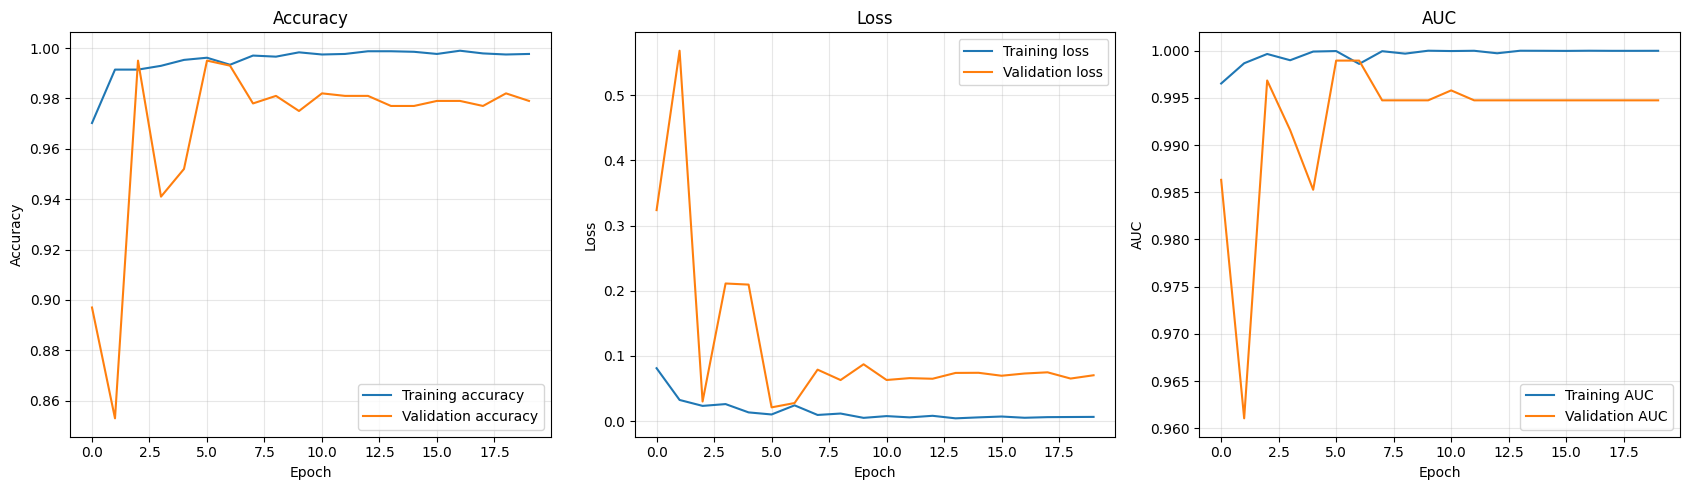


Loading best checkpoint: C:\Users\hadia\HED_XAI_TB_Results\HED_XAI_TB_Best.h5



Evaluating the held-out test set...
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 216ms/step - accuracy: 0.9950 - auc: 0.9989 - loss: 0.0232 - precision: 1.0000 - recall: 0.9895
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 220ms/step

FINAL TEST RESULTS -- HED-XAI-TB
Test loss:            0.0232
Accuracy:             99.50%
Precision:            100.00%
Sensitivity/Recall:   98.95%
Specificity:           100.00%
Negative predictive value: 99.06%
F1-score:              0.9947
ROC-AUC:               1.0000
PR-AUC (trapezoidal):  1.0000
Average precision:     1.0000
Confusion matrix (rows=actual, columns=predicted):
[[525   0]
 [  5 471]]
TN=525, FP=0, FN=5, TP=471

Classification report:
              precision    recall  f1-score   support

      Normal     0.9906    1.0000    0.9953       525
Tuberculosis     1.0000    0.9895    0.9947       476

    accuracy                         0.9950      1001
   macro avg     0.9953    0.9947    0.9950      1001
weighted avg     0.9951    0.9950    0.9950      1001



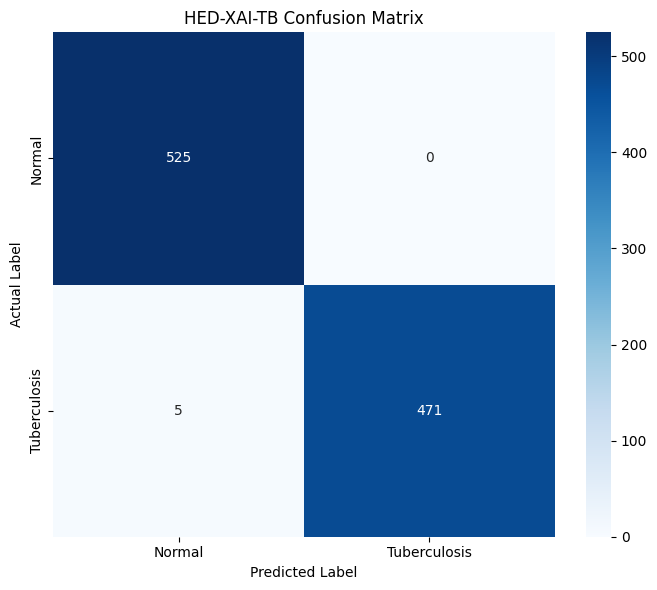

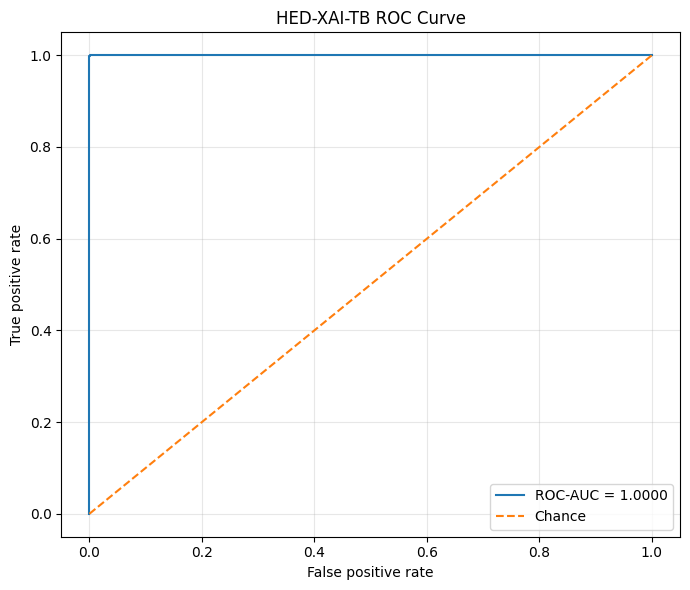

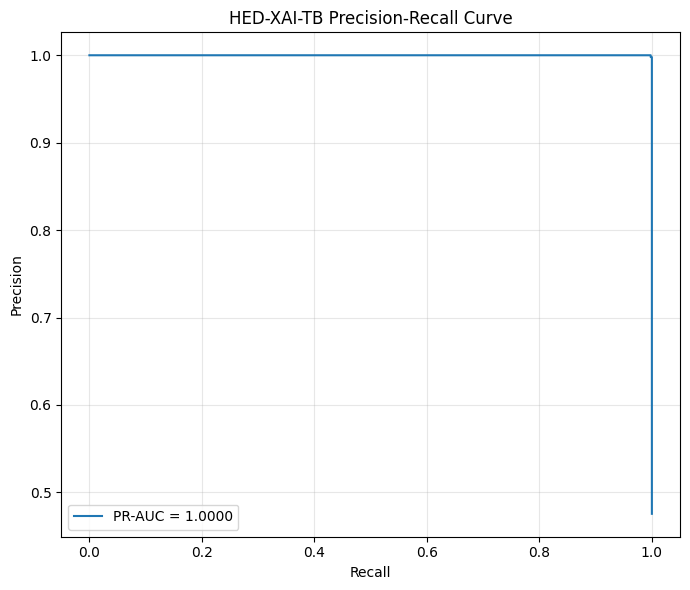


Final metrics table:
                              Metric                                                      Value
                               Model                                                 HED-XAI-TB
                        Architecture MobileNetV2 multi-scale feature fusion + channel attention
                      Positive class                                               Tuberculosis
                      Negative class                                                     Normal
                          Input size                                              224 x 224 x 3
                    Requested epochs                                                         20
                    Epochs completed                                                         20
          Best validation-loss epoch                                                          6
                          Batch size                                                         16
                Or

In [7]:
# ============================================================
# HED-XAI-TB: Hybrid Efficient Deep Learning for Tuberculosis
# Classification from Chest X-ray Images
#
# Proposed architecture:
#   MobileNetV2 multi-scale features
#   + channel-attention feature refinement
#   + feature fusion
#   + binary classifier
#
# This is a research prototype, not a clinically validated tool.
# Fixed training duration: 20 epochs.
#
# Expected dataset structure:
# dataset/
#   Normal/
#       image1.png
#       ...
#   Tuberculosis/
#       image1.png
#       ...
#
# Install packages in your TensorFlow environment:
# pip install tensorflow numpy pandas matplotlib scikit-learn pillow
# ============================================================

import os
import json
import time
import random
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    auc,
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    Concatenate,
    Multiply,
    Reshape,
    BatchNormalization,
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger,
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model


# ============================================================
# 1. CONFIGURATION -- EDIT THESE TWO PATHS
# ============================================================

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16           # Use 8 if RAM is limited; 32 if your computer supports it.
EPOCHS = 20               # Exactly 20 epochs; no early stopping.
LEARNING_RATE = 1e-4
FINE_TUNE_LAST_LAYERS = 30
THRESHOLD = 0.5

# IMPORTANT: Change BASE_PATH to the folder containing Normal and Tuberculosis.
BASE_PATH = r"D:\Downloads\Data Analysis\master\Thesis\data\Thesis_Dataset_and_Codes\dataset\TB_Chest_Radiography_Database"

# Output directory for model, CSV files, and figures.
OUTPUT_DIR = r"C:\Users\hadia\HED_XAI_TB_Results"

CLASS_NAMES = ["Normal", "Tuberculosis"]
VALID_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Best.h5")
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Final.h5")
RESULTS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Final_Metrics.csv")
REPORT_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Classification_Report.csv")
PREDICTIONS_CSV = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Test_Predictions.csv")
SPLIT_MANIFEST = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Split_Manifest.csv")
TRAINING_LOG = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Training_Log.csv")
CONFIG_FILE = os.path.join(OUTPUT_DIR, "HED_XAI_TB_Experiment_Config.json")

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 72)
print("HED-XAI-TB: HYBRID MULTI-SCALE ATTENTION MODEL")
print("=" * 72)
print("TensorFlow version:", tf.__version__)
print("Dataset:", BASE_PATH)
print("Output:", OUTPUT_DIR)
print("Epochs:", EPOCHS)


# ============================================================
# 2. VALIDATE DATASET AND LOAD IMAGE PATHS
# ============================================================

if not os.path.isdir(BASE_PATH):
    raise FileNotFoundError(
        f"\nDataset folder not found:\n{BASE_PATH}\n\n"
        "Edit BASE_PATH in Section 1 so it points to the folder "
        "that contains the Normal and Tuberculosis folders."
    )

for class_name in CLASS_NAMES:
    class_folder = os.path.join(BASE_PATH, class_name)
    if not os.path.isdir(class_folder):
        raise FileNotFoundError(
            f"Expected class folder was not found: {class_folder}\n"
            f"Your dataset must contain folders named exactly: {CLASS_NAMES}"
        )

records = []
for label, class_name in enumerate(CLASS_NAMES):
    class_folder = os.path.join(BASE_PATH, class_name)
    for file_path in sorted(Path(class_folder).rglob("*")):
        if file_path.is_file() and file_path.suffix.lower() in VALID_EXTENSIONS:
            records.append({
                "image_path": str(file_path),
                "label": label,
                "class_name": class_name,
            })

df = pd.DataFrame(records)
if df.empty:
    raise ValueError("No images were found. Check BASE_PATH and file extensions.")

print("\nOriginal image count:", len(df))
print(df["class_name"].value_counts().to_string())

if df["label"].nunique() != 2:
    raise ValueError("Both Normal and Tuberculosis classes must contain images.")


# ============================================================
# 3. REMOVE BYTE-IDENTICAL DUPLICATES BEFORE SPLITTING
# ============================================================
# SHA-256 removes exact file duplicates only. It does not detect all
# visually similar/recompressed images and does not ensure patient-level
# independence. If patient IDs are available, prefer patient-level splitting.

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


print("\nCalculating SHA-256 hashes to identify exact duplicate files...")
df["sha256"] = df["image_path"].apply(sha256_file)

hash_label_counts = df.groupby("sha256")["label"].nunique()
conflicting_hashes = hash_label_counts[hash_label_counts > 1]
if len(conflicting_hashes) > 0:
    raise ValueError(
        "Identical files have conflicting class labels. Please review the labels."
    )

original_count = len(df)
df = df.drop_duplicates(subset="sha256", keep="first").reset_index(drop=True)
duplicates_removed = original_count - len(df)

print("Exact duplicate files removed:", duplicates_removed)
print("Unique images retained:", len(df))
print(df["class_name"].value_counts().to_string())


# ============================================================
# 4. STRATIFIED 70 / 15 / 15 SPLIT
# ============================================================
# If images from the same patient can be identified, use patient-level
# splitting instead. Image-level splitting may overestimate performance
# when the same patient contributes multiple images.

train_df, temporary_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"],
)

val_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_df["label"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset split:")
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{split_name}: {len(split_df)} images")
    print(split_df["class_name"].value_counts().to_string())

# Verify exact files do not overlap.
assert set(train_df["sha256"]).isdisjoint(set(val_df["sha256"]))
assert set(train_df["sha256"]).isdisjoint(set(test_df["sha256"]))
assert set(val_df["sha256"]).isdisjoint(set(test_df["sha256"]))

manifest = pd.concat(
    [
        train_df.assign(split="train"),
        val_df.assign(split="validation"),
        test_df.assign(split="test"),
    ],
    ignore_index=True,
)
manifest.to_csv(SPLIT_MANIFEST, index=False)
print("\nSplit manifest saved:", SPLIT_MANIFEST)


# ============================================================
# 5. IMAGE GENERATORS
# ============================================================
# MobileNetV2 preprocess_input maps image values to its expected range.
# Augmentation is applied only to training images.

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.04,
    height_shift_range=0.04,
    zoom_range=0.08,
    horizontal_flip=True,
    fill_mode="nearest",
)

evaluation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="rgb",
    class_mode="raw",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_generator = evaluation_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="rgb",
    class_mode="raw",
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_generator = evaluation_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="rgb",
    class_mode="raw",
    batch_size=BATCH_SIZE,
    shuffle=False,
)


# ============================================================
# 6. BUILD THE PROPOSED HYBRID MODEL
# ============================================================
# HED-XAI-TB prototype:
#   (a) MobileNetV2 pretrained feature extractor
#   (b) multi-scale global feature extraction from three stages
#   (c) concatenation-based feature fusion
#   (d) channel-attention gate over fused features
#   (e) dense binary classification head
#
# This architecture is a proposed research design. Its novelty and value
# must be established by literature review and controlled ablation studies.

print("\nBuilding HED-XAI-TB model...")

backbone = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)

# Use outputs from early/middle/deep feature stages.
feature_layer_names = [
    "block_3_expand_relu",
    "block_6_expand_relu",
    "out_relu",
]
feature_outputs = [backbone.get_layer(name).output for name in feature_layer_names]
feature_extractor = Model(
    inputs=backbone.input,
    outputs=feature_outputs,
    name="MobileNetV2_MultiScale_Extractor",
)

# Freeze backbone, then fine-tune the final selected layers.
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False

for layer in backbone.layers[-FINE_TUNE_LAST_LAYERS:]:
    # Keep BatchNorm layers frozen for more stable transfer learning.
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="chest_xray_input")

# training=False keeps pretrained BatchNorm statistics stable.
multi_scale_maps = feature_extractor(inputs, training=False)

pooled_features = [
    GlobalAveragePooling2D(name=f"global_pool_scale_{i+1}")(feature_map)
    for i, feature_map in enumerate(multi_scale_maps)
]

fused = Concatenate(name="multi_scale_feature_fusion")(pooled_features)
fused = BatchNormalization(name="fusion_batch_norm")(fused)
fused = Dense(256, activation="relu", name="fusion_projection")(fused)
fused = Dropout(0.35, name="fusion_dropout")(fused)

# Channel-attention gate: learn a feature-wise importance vector.
attention_hidden_units = max(16, 256 // 8)
attention = Dense(
    attention_hidden_units,
    activation="relu",
    name="channel_attention_hidden",
)(fused)
attention = Dense(
    256,
    activation="sigmoid",
    name="channel_attention_weights",
)(attention)
attended = Multiply(name="channel_attention_refinement")([fused, attention])

x = Dense(128, activation="relu", name="classifier_dense")(attended)
x = Dropout(0.25, name="classifier_dropout")(x)
outputs = Dense(1, activation="sigmoid", name="tuberculosis_probability")(x)

model = Model(inputs=inputs, outputs=outputs, name="HED_XAI_TB")

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model.summary()


# ============================================================
# 7. SAVE CONFIGURATION AND CALLBACKS
# ============================================================

config = {
    "model_name": "HED-XAI-TB",
    "architecture": (
        "MobileNetV2 multi-scale feature extraction, concatenation-based "
        "feature fusion, channel-attention refinement, binary classifier"
    ),
    "input_size": [IMG_SIZE, IMG_SIZE, 3],
    "classes": {"Normal": 0, "Tuberculosis": 1},
    "split": "Stratified 70/15/15 after SHA-256 exact duplicate removal",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "fine_tune_last_layers": FINE_TUNE_LAST_LAYERS,
    "threshold": THRESHOLD,
    "seed": SEED,
    "preprocessing": "MobileNetV2 preprocess_input",
    "augmentation": {
        "rotation_range": 8,
        "width_shift_range": 0.04,
        "height_shift_range": 0.04,
        "zoom_range": 0.08,
        "horizontal_flip": True,
    },
}

with open(CONFIG_FILE, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=4)

checkpoint = ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1,
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1,
)

csv_logger = CSVLogger(TRAINING_LOG, append=False)
callbacks = [checkpoint, reduce_lr, csv_logger]


# ============================================================
# 8. TRAIN FOR EXACTLY 20 EPOCHS
# ============================================================
# No EarlyStopping callback is used, so training runs for all 20 epochs
# unless a runtime error or interruption occurs.

print("\nStarting training...")
training_start = time.perf_counter()

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

training_seconds = time.perf_counter() - training_start
actual_epochs = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

print("\nTraining completed.")
print("Epochs completed:", actual_epochs)
print("Best validation-loss epoch:", best_epoch)
print(f"Training time: {training_seconds:.2f} seconds")
print(f"Training time: {training_seconds / 60:.2f} minutes")

model.save(FINAL_MODEL_PATH)


# ============================================================
# 9. DISPLAY TRAINING HISTORY AND SAVE HISTORY CSV
# ============================================================

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_History.csv"),
    index=False,
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

if "auc" in history.history:
    axes[2].plot(history.history["auc"], label="Training AUC")
    axes[2].plot(history.history["val_auc"], label="Validation AUC")
axes[2].set_title("AUC")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("AUC")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 10. LOAD BEST VALIDATION CHECKPOINT
# ============================================================

print("\nLoading best checkpoint:", BEST_MODEL_PATH)
best_model = load_model(BEST_MODEL_PATH)


# ============================================================
# 11. TEST-SET EVALUATION AND INFERENCE TIMING
# ============================================================

print("\nEvaluating the held-out test set...")
test_generator.reset()
test_loss, test_accuracy, test_auc_keras, test_precision_keras, test_recall_keras = (
    best_model.evaluate(test_generator, verbose=1)
)

# Warm-up for a more stable inference timing estimate.
test_generator.reset()
warmup_images, _ = next(test_generator)
_ = best_model.predict(warmup_images[:min(4, len(warmup_images))], verbose=0)

test_generator.reset()
inference_start = time.perf_counter()
y_prob = best_model.predict(test_generator, verbose=1).ravel()
inference_seconds = time.perf_counter() - inference_start

y_true = test_df["label"].to_numpy(dtype=int)
if len(y_true) != len(y_prob):
    raise ValueError(
        f"Prediction count ({len(y_prob)}) does not match test labels ({len(y_true)})."
    )

y_pred = (y_prob >= THRESHOLD).astype(int)
test_count = len(y_true)
inference_ms_per_image = (inference_seconds / test_count) * 1000
throughput = test_count / inference_seconds if inference_seconds > 0 else 0.0


# ============================================================
# 12. CLASSIFICATION METRICS
# ============================================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0.0
npv = tn / (tn + fn) if (tn + fn) else 0.0
f1 = f1_score(y_true, y_pred, zero_division=0)

if len(np.unique(y_true)) == 2:
    roc_auc = roc_auc_score(y_true, y_prob)
    average_precision = average_precision_score(y_true, y_prob)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_recall, pr_precision)
else:
    roc_auc = float("nan")
    average_precision = float("nan")
    fpr, tpr = np.array([]), np.array([])
    pr_precision, pr_recall = np.array([]), np.array([])
    pr_auc = float("nan")

print("\n" + "=" * 72)
print("FINAL TEST RESULTS -- HED-XAI-TB")
print("=" * 72)
print(f"Test loss:            {test_loss:.4f}")
print(f"Accuracy:             {accuracy * 100:.2f}%")
print(f"Precision:            {precision * 100:.2f}%")
print(f"Sensitivity/Recall:   {sensitivity * 100:.2f}%")
print(f"Specificity:           {specificity * 100:.2f}%")
print(f"Negative predictive value: {npv * 100:.2f}%")
print(f"F1-score:              {f1:.4f}")
print(f"ROC-AUC:               {roc_auc:.4f}")
print(f"PR-AUC (trapezoidal):  {pr_auc:.4f}")
print(f"Average precision:     {average_precision:.4f}")
print("Confusion matrix (rows=actual, columns=predicted):")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
    output_dict=True,
)
pd.DataFrame(report_dict).transpose().to_csv(REPORT_CSV)


# ============================================================
# 13. SAVE TEST PREDICTIONS
# ============================================================

predictions_df = test_df.copy()
predictions_df["actual_class"] = predictions_df["label"].map({
    0: "Normal",
    1: "Tuberculosis",
})
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [
    CLASS_NAMES[int(value)] for value in y_pred
]
predictions_df["tuberculosis_probability"] = y_prob
predictions_df["correct_prediction"] = (
    predictions_df["label"].to_numpy() == y_pred
)
predictions_df.to_csv(PREDICTIONS_CSV, index=False)


# ============================================================
# 14. DISPLAY CONFUSION MATRIX, ROC AND PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("HED-XAI-TB Confusion Matrix")
plt.tight_layout()
plt.show()

if len(fpr) > 0:
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("HED-XAI-TB ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 6))
    plt.plot(pr_recall, pr_precision, label=f"PR-AUC = {pr_auc:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("HED-XAI-TB Precision-Recall Curve")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 15. MODEL SIZE, PARAMETERS AND FINAL METRICS TABLE
# ============================================================

total_params = best_model.count_params()
trainable_params = int(sum(
    np.prod(variable.shape) for variable in best_model.trainable_weights
))
non_trainable_params = int(sum(
    np.prod(variable.shape) for variable in best_model.non_trainable_weights
))
model_size_mb = os.path.getsize(BEST_MODEL_PATH) / (1024 ** 2)

results = [
    ("Model", "HED-XAI-TB"),
    ("Architecture", "MobileNetV2 multi-scale feature fusion + channel attention"),
    ("Positive class", "Tuberculosis"),
    ("Negative class", "Normal"),
    ("Input size", f"{IMG_SIZE} x {IMG_SIZE} x 3"),
    ("Requested epochs", EPOCHS),
    ("Epochs completed", actual_epochs),
    ("Best validation-loss epoch", best_epoch),
    ("Batch size", BATCH_SIZE),
    ("Original image files", original_count),
    ("Exact duplicates removed", duplicates_removed),
    ("Unique images retained", len(df)),
    ("Training images", len(train_df)),
    ("Validation images", len(val_df)),
    ("Test images", len(test_df)),
    ("Test loss", float(test_loss)),
    ("Test accuracy (%)", accuracy * 100),
    ("Precision (%)", precision * 100),
    ("Sensitivity (%)", sensitivity * 100),
    ("Specificity (%)", specificity * 100),
    ("Negative predictive value (%)", npv * 100),
    ("F1-score", f1),
    ("ROC-AUC", roc_auc),
    ("PR-AUC", pr_auc),
    ("Average precision", average_precision),
    ("True negative", int(tn)),
    ("False positive", int(fp)),
    ("False negative", int(fn)),
    ("True positive", int(tp)),
    ("Total parameters", int(total_params)),
    ("Trainable parameters", trainable_params),
    ("Non-trainable parameters", non_trainable_params),
    ("Best model size (MB)", model_size_mb),
    ("Training time (seconds)", training_seconds),
    ("Training time (minutes)", training_seconds / 60),
    ("Test inference time (seconds)", inference_seconds),
    ("Inference time per image (ms)", inference_ms_per_image),
    ("Inference time per image (seconds)", inference_seconds / test_count if test_count else 0.0),
    ("Inference throughput (images/second)", throughput),
    ("Decision threshold", THRESHOLD),
    ("Random seed", SEED),
]
results_df = pd.DataFrame(results, columns=["Metric", "Value"])
results_df.to_csv(RESULTS_CSV, index=False)

print("\nFinal metrics table:")
print(results_df.to_string(index=False))

print("\nSaved outputs:")
for path in [
    BEST_MODEL_PATH,
    FINAL_MODEL_PATH,
    RESULTS_CSV,
    REPORT_CSV,
    PREDICTIONS_CSV,
    SPLIT_MANIFEST,
    TRAINING_LOG,
    CONFIG_FILE,
    os.path.join(OUTPUT_DIR, "HED_XAI_TB_History.csv"),
]:
    print(" -", path)

print(f"Requested epochs: {EPOCHS}")
print(f"Completed epochs: {actual_epochs}")
print(f"Total training time: {training_seconds:.2f} seconds ({training_seconds / 60:.2f} minutes)")
print(f"Mean inference time per image: {inference_ms_per_image:.4f} ms")
print(f"Results directory: {OUTPUT_DIR}")
print("\nTraining and evaluation script completed.")
print("Evaluation plots are displayed on screen only; no plot images are saved.")
print("Use the best checkpoint for Grad-CAM analysis.")
print("Research note: validate the proposed contribution with ablations and external data.")
